In [2]:
import pandas as pd
import numpy as np
import sklearn
import re
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [3]:
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...


True

# Basic Pre-processing

In [4]:
df = pd.read_csv("Suicide_Detection (1).csv")

# Rename 'Unnamed' column
df = df.rename(columns={'Unnamed: 0': 'ID'})

# Drop rows with missing values in the 'class' column
df = df.dropna(subset=['class'])

In [5]:
df.head()

,ID,text,class
0,2,Ex Wife Threatening SuicideRecently I left my ...,suicide
1,3,Am I weird I don't get affected by compliments...,non-suicide
2,4,Finally 2020 is almost over... So I can never ...,non-suicide
3,8,i need helpjust help me im crying so hard,suicide
4,9,"I’m so lostHello, my name is Adam (16) and I’v...",suicide


In [6]:
df.isnull().sum()

ID       0
text     0
class    0
dtype: int64

# Cleaning along with other NLP Techniques for processing text: Tokenization, Lowercased-test, Filtered-text, Stopwords and Lemmatization

In [7]:
def clean_text(text):
    text = re.sub(r'[^a-zA-Z\s]', '', text)  # Remove non-alphabetic characters
    text = ' '.join(text.split())  # Remove extra whitespaces
    return text

# Apply the cleaning function to the 'text' column
df['cleaned_text'] = df['text'].apply(clean_text)

# Tokenization
df['tokenized_text'] = df['cleaned_text'].apply(word_tokenize)

# Lowercasing
df['lowercased_text'] = df['tokenized_text'].apply(lambda x: [word.lower() for word in x])

# Removing stopwords
stop_words = set(stopwords.words('english'))
df['filtered_text'] = df['lowercased_text'].apply(lambda x: [word for word in x if word not in stop_words])

# Lemmatization
lemmatizer = WordNetLemmatizer()
df['lemmatized_text'] = df['filtered_text'].apply(lambda x: [lemmatizer.lemmatize(word) for word in x])

In [8]:
df.head()

,ID,text,class,cleaned_text,tokenized_text,lowercased_text,filtered_text,lemmatized_text
0,2,Ex Wife Threatening SuicideRecently I left my ...,suicide,Ex Wife Threatening SuicideRecently I left my ...,"[Ex, Wife, Threatening, SuicideRecently, I, le...","[ex, wife, threatening, suiciderecently, i, le...","[ex, wife, threatening, suiciderecently, left,...","[ex, wife, threatening, suiciderecently, left,..."
1,3,Am I weird I don't get affected by compliments...,non-suicide,Am I weird I dont get affected by compliments ...,"[Am, I, weird, I, dont, get, affected, by, com...","[am, i, weird, i, dont, get, affected, by, com...","[weird, dont, get, affected, compliments, comi...","[weird, dont, get, affected, compliment, comin..."
2,4,Finally 2020 is almost over... So I can never ...,non-suicide,Finally is almost over So I can never hear has...,"[Finally, is, almost, over, So, I, can, never,...","[finally, is, almost, over, so, i, can, never,...","[finally, almost, never, hear, bad, year, ever...","[finally, almost, never, hear, bad, year, ever..."
3,8,i need helpjust help me im crying so hard,suicide,i need helpjust help me im crying so hard,"[i, need, helpjust, help, me, im, crying, so, ...","[i, need, helpjust, help, me, im, crying, so, ...","[need, helpjust, help, im, crying, hard]","[need, helpjust, help, im, cry, hard]"
4,9,"I’m so lostHello, my name is Adam (16) and I’v...",suicide,Im so lostHello my name is Adam and Ive been s...,"[Im, so, lostHello, my, name, is, Adam, and, I...","[im, so, losthello, my, name, is, adam, and, i...","[im, losthello, name, adam, ive, struggling, y...","[im, losthello, name, adam, ive, struggling, y..."


# Encoding the target column into 1s and 0s

In [9]:
#Unique values in class
print(df['class'].unique())
# Create binary for class column
df['class_binary'] = df['class'].map({'suicide': 1, 'non-suicide': 0})

['suicide' 'non-suicide']


In [10]:
df.head()

,ID,text,class,cleaned_text,tokenized_text,lowercased_text,filtered_text,lemmatized_text,class_binary
0,2,Ex Wife Threatening SuicideRecently I left my ...,suicide,Ex Wife Threatening SuicideRecently I left my ...,"[Ex, Wife, Threatening, SuicideRecently, I, le...","[ex, wife, threatening, suiciderecently, i, le...","[ex, wife, threatening, suiciderecently, left,...","[ex, wife, threatening, suiciderecently, left,...",1
1,3,Am I weird I don't get affected by compliments...,non-suicide,Am I weird I dont get affected by compliments ...,"[Am, I, weird, I, dont, get, affected, by, com...","[am, i, weird, i, dont, get, affected, by, com...","[weird, dont, get, affected, compliments, comi...","[weird, dont, get, affected, compliment, comin...",0
2,4,Finally 2020 is almost over... So I can never ...,non-suicide,Finally is almost over So I can never hear has...,"[Finally, is, almost, over, So, I, can, never,...","[finally, is, almost, over, so, i, can, never,...","[finally, almost, never, hear, bad, year, ever...","[finally, almost, never, hear, bad, year, ever...",0
3,8,i need helpjust help me im crying so hard,suicide,i need helpjust help me im crying so hard,"[i, need, helpjust, help, me, im, crying, so, ...","[i, need, helpjust, help, me, im, crying, so, ...","[need, helpjust, help, im, crying, hard]","[need, helpjust, help, im, cry, hard]",1
4,9,"I’m so lostHello, my name is Adam (16) and I’v...",suicide,Im so lostHello my name is Adam and Ive been s...,"[Im, so, lostHello, my, name, is, Adam, and, I...","[im, so, losthello, my, name, is, adam, and, i...","[im, losthello, name, adam, ive, struggling, y...","[im, losthello, name, adam, ive, struggling, y...",1


In [11]:
df.isnull().sum()

ID                 0
text               0
class              0
cleaned_text       0
tokenized_text     0
lowercased_text    0
filtered_text      0
lemmatized_text    0
class_binary       0
dtype: int64

# Using Word2Vec vectorization

In [12]:
from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

In [13]:
# Load the Word2Vec model
word2vec_model = Word2Vec(sentences=df['lemmatized_text'], vector_size=100, window=5, min_count=1, workers=4)

# Function to convert a sentence to the average of its word vectors
def get_sentence_vector(words, model, vector_size):
    vector = np.zeros(vector_size)
    count = 0
    for word in words:
        if word in model.wv:
            vector += model.wv[word]
            count += 1
    if count != 0:
        vector /= count
    return vector

# Apply the function to the lemmatized text
df['word2vec_features'] = df['lemmatized_text'].apply(lambda x: get_sentence_vector(x, word2vec_model, 100))


In [41]:
df.head()

,ID,text,class,cleaned_text,tokenized_text,lowercased_text,filtered_text,lemmatized_text,class_binary,word2vec_features
0,2,Ex Wife Threatening SuicideRecently I left my ...,suicide,Ex Wife Threatening SuicideRecently I left my ...,"[Ex, Wife, Threatening, SuicideRecently, I, le...","[ex, wife, threatening, suiciderecently, i, le...","[ex, wife, threatening, suiciderecently, left,...","[ex, wife, threatening, suiciderecently, left,...",1,"[0.18293292684266196, 0.3544187810907643, -0.0..."
1,3,Am I weird I don't get affected by compliments...,non-suicide,Am I weird I dont get affected by compliments ...,"[Am, I, weird, I, dont, get, affected, by, com...","[am, i, weird, i, dont, get, affected, by, com...","[weird, dont, get, affected, compliments, comi...","[weird, dont, get, affected, compliment, comin...",0,"[0.22588892773325955, 0.3179226543288678, -0.1..."
2,4,Finally 2020 is almost over... So I can never ...,non-suicide,Finally is almost over So I can never hear has...,"[Finally, is, almost, over, So, I, can, never,...","[finally, is, almost, over, so, i, can, never,...","[finally, almost, never, hear, bad, year, ever...","[finally, almost, never, hear, bad, year, ever...",0,"[0.14706025992266156, 0.40590583871711383, -0...."
3,8,i need helpjust help me im crying so hard,suicide,i need helpjust help me im crying so hard,"[i, need, helpjust, help, me, im, crying, so, ...","[i, need, helpjust, help, me, im, crying, so, ...","[need, helpjust, help, im, crying, hard]","[need, helpjust, help, im, cry, hard]",1,"[0.3024564025302728, 0.18132265082870921, 0.07..."
4,9,"I’m so lostHello, my name is Adam (16) and I’v...",suicide,Im so lostHello my name is Adam and Ive been s...,"[Im, so, lostHello, my, name, is, Adam, and, I...","[im, so, losthello, my, name, is, adam, and, i...","[im, losthello, name, adam, ive, struggling, y...","[im, losthello, name, adam, ive, struggling, y...",1,"[0.01541352547149721, 0.25693991210759565, 0.0..."


# Creating a model using logistic regression

In [53]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(df['word2vec_features'].to_list(), df['class_binary'], test_size=0.2, random_state=42)

# Create a logistic regression model, after applying gridsearch, the best value for C and max_iter have been found to be 100 and 500
logreg_model = LogisticRegression(C=100, max_iter=500)

# Fit the model
logreg_model.fit(X_train, y_train)

C:\Users\Admin\nidcatpythonlab\Lib\site-packages\sklearn\linear_model\_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(C=100, max_iter=500)

In [54]:
predictions = logreg_model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, predictions)
print(f'Accuracy: {accuracy:.2f}')

Accuracy: 0.87


In [56]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions)
recall = recall_score(y_test, predictions)
f1 = f1_score(y_test, predictions)
conf_matrix = confusion_matrix(y_test, predictions)

print(f'Accuracy: {accuracy:.2f}')
print(f'Precision: {precision:.2f}')
print(f'Recall: {recall:.2f}')
print(f'F1 Score: {f1:.2f}')
print('Confusion Matrix:')
print(conf_matrix)

Accuracy: 0.87
Precision: 0.86
Recall: 0.88
F1 Score: 0.87
Confusion Matrix:
[[638 111]
 [ 90 665]]


# Creating a model using a Recurrent neural network

In [44]:
from keras.models import Sequential
from keras.layers import Embedding, LSTM, Dense
from keras.preprocessing.text import Tokenizer
from keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Tokenize and pad the text data
max_words = 5000  # Maximum number of words to keep
max_len = 100  # Maximum length of sequences
tokenizer = Tokenizer(num_words=max_words, split=' ')
tokenizer.fit_on_texts(df['lemmatized_text'])
sequences = tokenizer.texts_to_sequences(df['lemmatized_text'])
X = pad_sequences(sequences, maxlen=100)

Epoch 1/5
151/151 [==============================] - 34s 182ms/step - loss: 0.4173 - accuracy: 0.8277 - val_loss: 0.3079 - val_accuracy: 0.9003
Epoch 2/5
151/151 [==============================] - 25s 162ms/step - loss: 0.1970 - accuracy: 0.9287 - val_loss: 0.2819 - val_accuracy: 0.8978
Epoch 3/5
151/151 [==============================] - 25s 164ms/step - loss: 0.1300 - accuracy: 0.9562 - val_loss: 0.3369 - val_accuracy: 0.8929
Epoch 4/5
151/151 [==============================] - 23s 155ms/step - loss: 0.1068 - accuracy: 0.9645 - val_loss: 0.3459 - val_accuracy: 0.8945
Epoch 5/5
151/151 [==============================] - 25s 163ms/step - loss: 0.0888 - accuracy: 0.9715 - val_loss: 0.3672 - val_accuracy: 0.8945


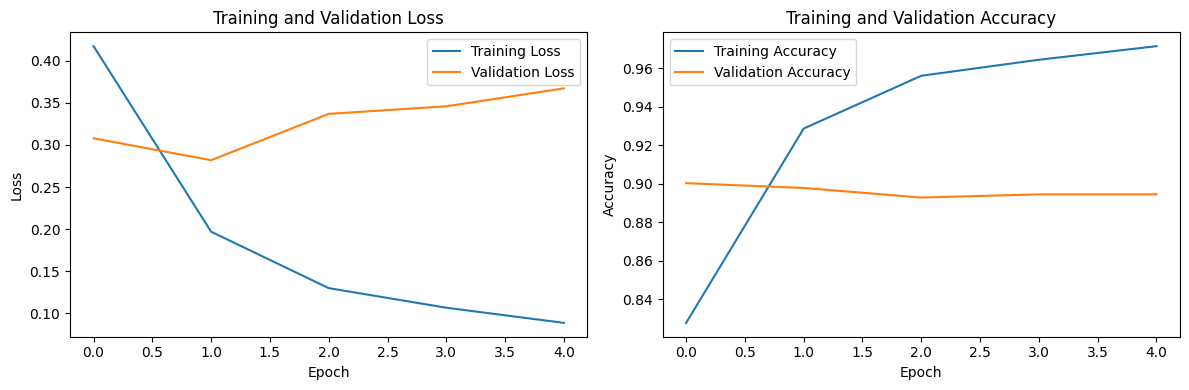

In [50]:
from tensorflow.keras.callbacks import EarlyStopping
from keras.layers import Dropout
X_train, X_test, y_train, y_test = train_test_split(X, df['class_binary'], test_size=0.2, random_state=42)

# Create the RNN model
model = Sequential()
model.add(Embedding(input_dim=len(tokenizer.word_index) + 1, output_dim=100, input_length=100))
model.add(LSTM(100))  # You can adjust the number of LSTM units
model.add(Dropout(0.5))
model.add(Dense(1, activation='sigmoid'))

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
import matplotlib.pyplot as plt
# Train the model and record the history
history = model.fit(X_train, y_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[early_stopping])

# Extract training history
train_loss = history.history['loss']
val_loss = history.history['val_loss']
train_acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

# Plot training and validation loss
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(train_loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Plot training and validation accuracy
plt.subplot(1, 2, 2)
plt.plot(train_acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()


In [51]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
# Evaluate the model on the test set
predictions = (model.predict(X_test) > 0.5).astype(int)
accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions)
recall = recall_score(y_test, predictions)
f1 = f1_score(y_test, predictions)
conf_matrix = confusion_matrix(y_test, predictions)

print(f'Accuracy: {accuracy:.2f}')
print(f'Precision: {precision:.2f}')
print(f'Recall: {recall:.2f}')
print(f'F1 Score: {f1:.2f}')
print('Confusion Matrix:')
print(conf_matrix)


47/47 [==============================] - 3s 39ms/step
Accuracy: 0.90
Precision: 0.93
Recall: 0.86
F1 Score: 0.89
Confusion Matrix:
[[701  48]
 [107 648]]
